# 30 · Reductions

How should a one-step regressor reach 36 steps ahead? Reduce the same Ridge pipeline three ways, score the reductions on identical cases with the usual report, then follow the error horizon by horizon to see where recursive errors accumulate and when they do not.

## Run this notebook

From the repository root, install `python -m pip install -e '.[notebooks]'`, then launch `python -m jupyterlab notebooks`. Use that Python kernel and run all cells in order. See the [notebook guide](README.md). This application is self-contained and runs locally. Each comparison uses 40 independent series and 36 horizons; the random forest section uses 20.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

import timegym
from timegym import Pipeline, Scenario
from timegym.models import REDUCTIONS
from timegym.statistics import paired_t_interval

%matplotlib inline
plt.rcParams.update({"figure.figsize": (12, 4), "figure.dpi": 110, "font.size": 11,
                     "figure.facecolor": "white", "axes.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "legend.frameon": False, "axes.titlelocation": "left"})
COLORS = {"recursive": "#D55E00", "direct": "#0000CC", "multioutput": "#009E73"}
print(f"TimeGym {timegym.__version__} | NumPy {np.__version__} | pandas {pd.__version__}")

TimeGym 1.0.0 | NumPy 2.5.4 | pandas 3.1.0


## Reduce one regressor three ways

Every reduction trains on the same lag windows of the context and fits the scaler on those training rows only. **Recursive** fits a one-step regressor and feeds its own predictions back into the window. **Direct** fits one regressor per horizon step, each from observed windows. **Multioutput** fits one regressor whose output is the whole horizon vector. The window holds 4 months of a 12-month season, a third of the cycle, so the one-step model is short-sighted on purpose.

All three pipelines run on the same scenario and seeds, so every reduction sees the same contexts, origins, and held-out values.

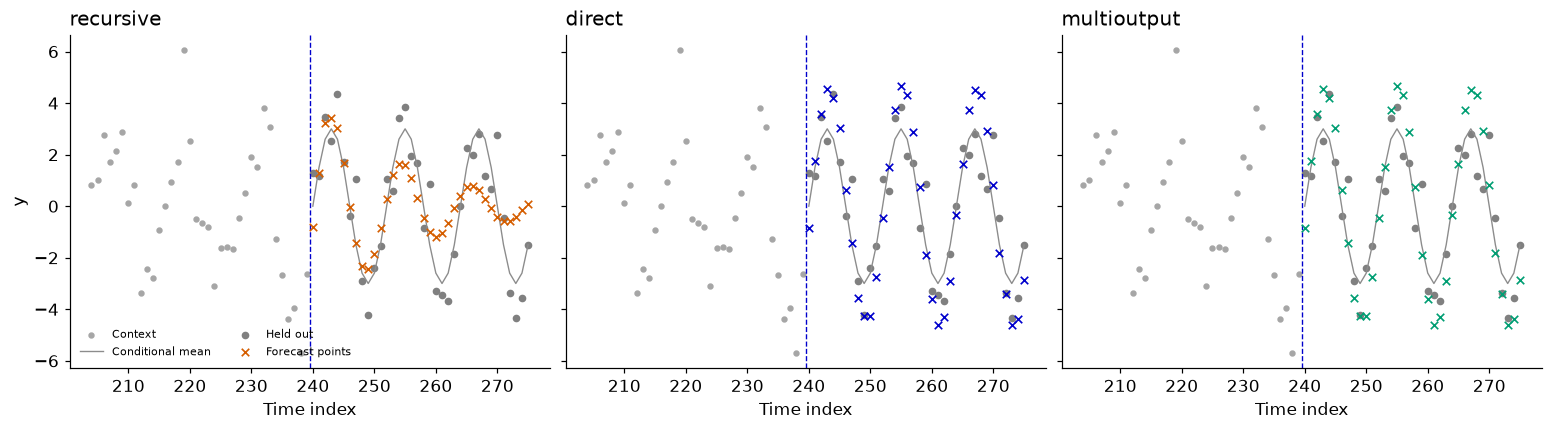

In [2]:
HORIZON, WINDOW = 36, 4
SEEDS = range(40)
seasonal = Scenario("seasonal", context_length=240, horizon=HORIZON,
                    parameters={"amplitude": 3., "period": 12., "sigma": 1.})


def scaled_ridge(reduction):
    return Pipeline(window_length=WINDOW, reduction=reduction).add(StandardScaler()).add(Ridge(alpha=1.))


runs = {reduction: scaled_ridge(reduction).run([seasonal], seeds=SEEDS) for reduction in REDUCTIONS}
for reduction, run in runs.items():
    assert run.metadata["reduction"] == run.metadata["pipeline_config"]["reduction"] == reduction
    assert run.report.summary["failed_cases"] == 0
    for entry, first in zip(run.cases, runs["recursive"].cases):
        pd.testing.assert_frame_equal(entry.case.task.context, first.case.task.context)
        pd.testing.assert_frame_equal(entry.case.observed, first.case.observed)

example = 0
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True, constrained_layout=True)
for ax, (reduction, run) in zip(axes, runs.items()):
    entry = run.cases[example]
    context = entry.case.task.context.iloc[-36:]
    ax.scatter(context.index, context.iloc[:, 0], color="0.65", s=10, label="Context")
    ax.plot(entry.case.reference.index, entry.case.reference.mean[:, 0], color="0.55", linewidth=.9,
            label="Conditional mean")
    ax.scatter(entry.case.observed.index, entry.case.observed.iloc[:, 0], color="0.5", s=16, label="Held out")
    ax.scatter(entry.forecast.index, entry.forecast.point[:, 0], marker="x", color=COLORS[reduction], s=24,
               linewidths=1.1, label="Forecast points", zorder=4)
    ax.axvline(entry.forecast.index[0] - .5, color="#0000CC", linestyle="--", linewidth=.9)
    ax.set(title=reduction, xlabel="Time index")
axes[0].set_ylabel("y")
axes[0].legend(fontsize=7.5, loc="lower left", ncol=2)
plt.show()

In this series the recursive forecast drifts away from the cycle, its amplitude and timing slipping as its own predictions fill the window. The direct and multioutput forecasts keep both, because each horizon is learned from observed windows, not from earlier forecasts.

## Score them with the report

`run.report` is the usual `TestReport`, with whole-case scores for every series: mean-reference MSE measures the squared distance from the known conditional mean, MSE the distance from the held-out values. Pair the reductions within each series, then summarize the differences across independent series.

In [3]:
scores = pd.DataFrame([{"reduction": reduction, "seed": result.seed,
                        "Mean-reference MSE": result.metrics["mean_reference_mse"],
                        "MSE": result.metrics["mse"], "MAE": result.metrics["mae"]}
                       for reduction, run in runs.items() for result in run.report.cases])
display(scores.groupby("reduction", sort=False)[["Mean-reference MSE", "MSE", "MAE"]].mean().round(3))

table = scores.pivot(index="seed", columns="reduction", values="Mean-reference MSE")
np.testing.assert_allclose(table["direct"], table["multioutput"], rtol=1e-8)
intervals = {f"{reduction} - recursive": paired_t_interval(table[reduction] - table["recursive"])
             for reduction in ("direct", "multioutput")}
display(pd.DataFrame({name: {"mean difference": interval["mean"], "lower 95%": interval["ci95"][0],
                             "upper 95%": interval["ci95"][1], "independent series": interval["n"]}
                      for name, interval in intervals.items()}).T.round(3))

,Mean-reference MSE,MSE,MAE
reduction,,,
recursive,2.477,3.482,1.537
direct,0.556,1.578,1.006
multioutput,0.556,1.578,1.006


,mean difference,lower 95%,upper 95%,independent series
direct - recursive,-1.921,-2.145,-1.697,40.0
multioutput - recursive,-1.921,-2.145,-1.697,40.0


Negative differences favour the named reduction over recursion. Multioutput and direct agree to rounding error: Ridge solves each output by the same penalized least squares on the same inputs, so fitting the horizon vector at once changes nothing. Whole-case scores average over 36 dependent horizons; they do not say where the difference arises.

## Where does recursive error accumulate?

Average the squared distance to the known conditional mean at each horizon over the independent series. Bands are pointwise 95% Student t intervals across series; neighbouring horizons of one series are dependent, so the bands are not a simultaneous region.

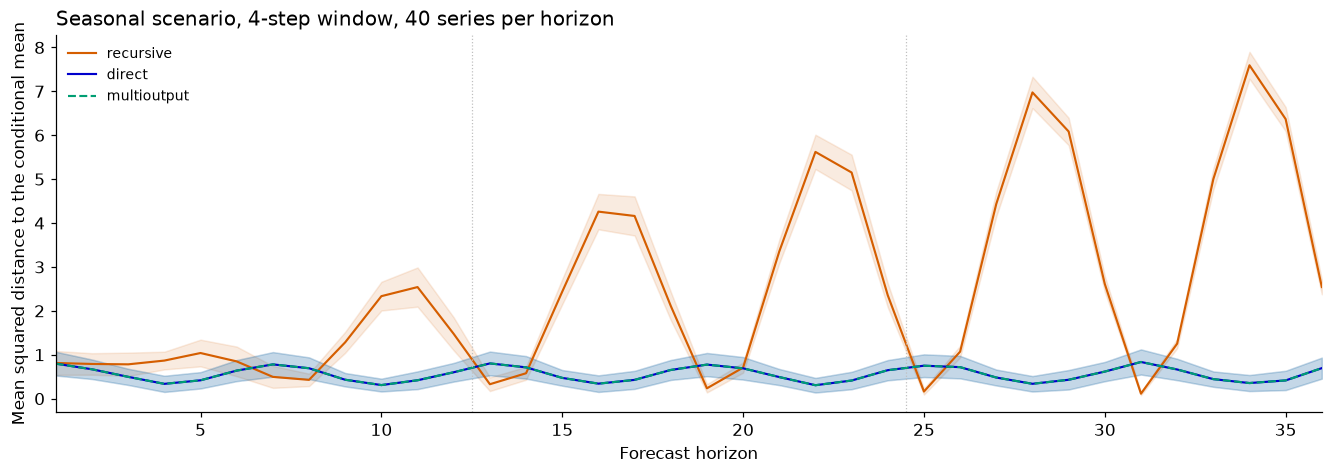

In [4]:
def plot_error_by_horizon(runs, title):
    fig, ax = plt.subplots(figsize=(12, 4.2), constrained_layout=True)
    horizons = np.arange(1, HORIZON + 1)
    for reduction, run in runs.items():
        errors = np.asarray([((entry.forecast.point - entry.case.reference.mean) ** 2)[:, 0]
                             for entry in run.cases])
        mean = errors.mean(axis=0)
        half = stats.t.ppf(.975, len(errors) - 1) * errors.std(axis=0, ddof=1) / np.sqrt(len(errors))
        style = "--" if reduction == "multioutput" else "-"
        ax.plot(horizons, mean, style, color=COLORS[reduction], linewidth=1.4, label=reduction)
        ax.fill_between(horizons, mean - half, mean + half, color=COLORS[reduction], alpha=.12)
    for boundary in (12.5, 24.5):
        ax.axvline(boundary, color="0.75", linewidth=.8, linestyle=":")
    ax.set(xlabel="Forecast horizon", ylabel="Mean squared distance to the conditional mean",
           xlim=(1, HORIZON), title=title)
    ax.legend(fontsize=9, loc="upper left")
    plt.show()


plot_error_by_horizon(runs, f"Seasonal scenario, {WINDOW}-step window, {len(SEEDS)} series per horizon")

Recursive error oscillates with the season, and its peaks rise from one season to the next. Four lags are too few to pin down the cycle, and every prediction the recursive model feeds back carries its error into the next input, so the error compounds. Direct and multioutput errors repeat their first-season pattern, because no horizon depends on an earlier forecast. Dotted lines mark the season boundaries.

## When the one-step model is right

Accumulation needs a misspecified one-step model. Repeat the comparison on a stationary AR(1), where the latest value carries everything the next one depends on, so four lags are more than enough.

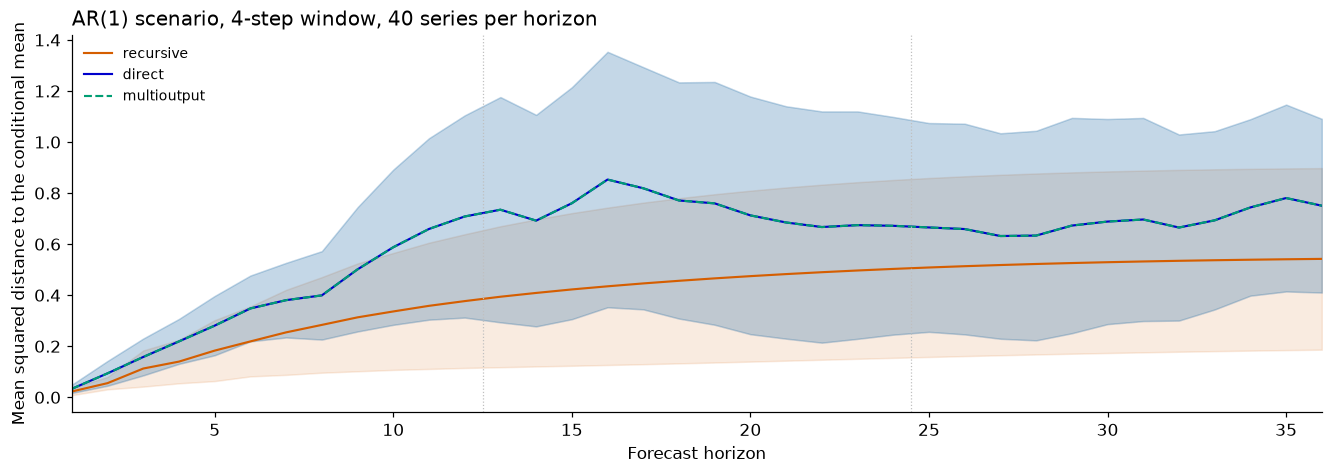

Direct minus recursive mean-reference MSE: 0.194 (95% interval -0.086 to 0.474, 40 series)


In [5]:
ar1 = Scenario("ar1", context_length=240, horizon=HORIZON, parameters={"phi": .9, "sigma": 1.})
ar1_runs = {reduction: scaled_ridge(reduction).run([ar1], seeds=SEEDS) for reduction in REDUCTIONS}
plot_error_by_horizon(ar1_runs, f"AR(1) scenario, {WINDOW}-step window, {len(SEEDS)} series per horizon")
ar1_scores = pd.DataFrame({reduction: [result.metrics["mean_reference_mse"] for result in run.report.cases]
                           for reduction, run in ar1_runs.items()})
interval = paired_t_interval(ar1_scores["direct"] - ar1_scores["recursive"])
print(f"Direct minus recursive mean-reference MSE: {interval['mean']:.3f} "
      f"(95% interval {interval['ci95'][0]:.3f} to {interval['ci95'][1]:.3f}, {interval['n']} series)")

Here the recursive error levels off as its forecast settles towards the mean: nothing compounds. Its average stays below the direct average at every horizon, because each direct regressor estimates its own long-range relation from labels that grow noisier with the horizon. With 40 series the bands overlap and the whole-case interval includes zero, so this shows the absence of accumulation, not a decisive ranking. Error accumulation is a symptom of a misspecified one-step model, not of recursion itself.

## When multioutput differs from direct

Ridge cannot tell multioutput from direct. A random forest can: a multioutput forest grows each tree to fit all 36 outputs at once and shares its splits across horizons, while direct grows a separate forest for every step. Trees need no scaler. This comparison uses 20 of the 40 seasonal series to keep the run short.

In [6]:
forest = RandomForestRegressor(n_estimators=30, min_samples_leaf=5, random_state=0)
forest_runs = {reduction: Pipeline(forest, window_length=WINDOW, reduction=reduction)
               .run([seasonal], seeds=SEEDS[:20]) for reduction in REDUCTIONS}
forest_scores = pd.DataFrame({reduction: [result.metrics["mean_reference_mse"] for result in run.report.cases]
                              for reduction, run in forest_runs.items()})
display(forest_scores.mean().rename("Mean-reference MSE").to_frame().T.round(3))
interval = paired_t_interval(forest_scores["multioutput"] - forest_scores["direct"])
print(f"Multioutput minus direct: {interval['mean']:.3f} "
      f"(95% interval {interval['ci95'][0]:.3f} to {interval['ci95'][1]:.3f}, {interval['n']} series)")

,recursive,direct,multioutput
Mean-reference MSE,0.752,0.457,0.347


Multioutput minus direct: -0.110 (95% interval -0.174 to -0.046, 20 series)


The forest repeats the recursive penalty, and here the shared multioutput forest is also more accurate than the per-step forests. For an estimator that pools information across outputs, multioutput is a different model, not a faster way to fit direct.

## Change one thing

- Set `WINDOW = 12`, a full season, and check whether the recursive error still compounds.
- Raise `sigma` in the seasonal scenario and watch the one-step fit, and the recursive error, degrade.
- Replace Ridge with `SVR()`. It has no native multioutput support, so the multioutput reduction wraps it in `MultiOutputRegressor` and matches direct again.
- Add a `target_transform` from [29 · Target transforms](29_target_transforms.ipynb); the reduction and the transform are independent settings.

**Scope.** Two Gaussian processes, one window, and two regressor families show the mechanism; they do not rank reductions in general. Intervals are pointwise and descriptive, with no acceptance threshold. Reductions return point forecasts, so uncertainty checks stay unsupported.

Continue with the [tutorial overview](../docs/notebooks.md). Reading: [Ben Taieb et al. (2012)](https://doi.org/10.1016/j.eswa.2012.01.039).